# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_: 
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how both Euler's method and Runge-Kutta method work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Abellana, Karl Gian
- _Student No._: 2024-09545
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

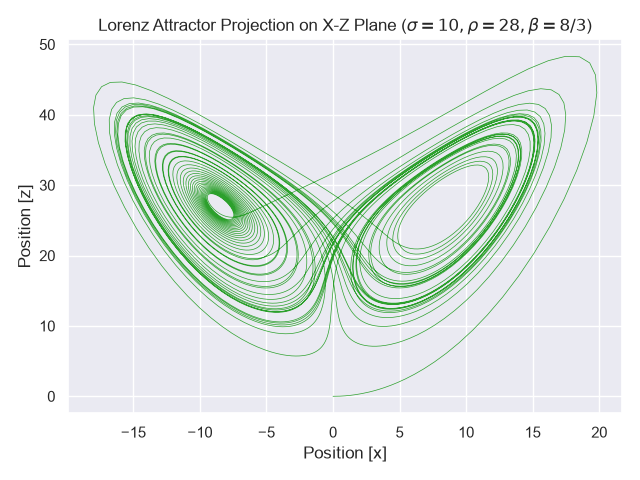

Figure 1. The plot of the Lorenz Attractor projection on the x - z plane, also known as the "Lorenz Butterfly". With parameters $\sigma = 10, \rho = 28, \beta = \frac{8}{3}$ 

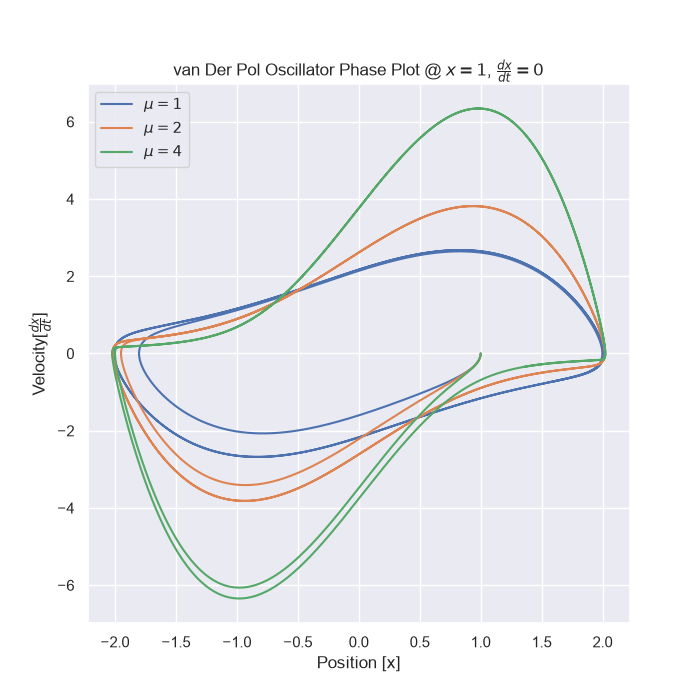

Figure 2. The phase plot of the van Der Pol Oscillation with initial conditions $x = 1, \frac{dx}{dt} = 0$ with $\mu = 1, 2, 4$


### Report discussion

**Dynamics in the figures**

In figure 1, there are two "loops" that seem to be moving outward. The trajectory goes around one of the loops around the center, as it moves outwards enough, it flies to the other loop and then starts to loop around there instead, repeating the process as it moves outwards enough. It also seems like the path never repeats or close.

In figure 2, the velocity (decreases, increases) as the position is initially (positive, negative), it gets maximally (negative, positive) by $x = \mp 1$ and then velocity starts (increasing, decreasing) again. This regulation of velocity keeps the trajectory bounded between $x \in [-2,2]\; \forall\; \mu = 1, 2, 4$. Note that the velocity peaks are smaller in $\mu = 1$ and get larger in the subsequent $\mu$. Compared to the Lorenz attractor, this is a closed and periodic loop.

**How the Euler's method and Runge-Kutta method work**

In this activity, we are introduced to two ways to solve ordinary differential equations; Euler's Method and Runge-Kutta (RK4) method. Euler's method uses the slope calculated at the current point to move forward a step at a time (h * slope) in order to approximate numerical solution to the differential equations $\frac{dy}{dt} = f(t,y)$ starting from initial conditions. Meanwhile, RK4 essentially does the same thing, except it samples four different slopes across each step; the first step uses slope calculated at current point, second and third step both use the previously calculated slope at half the step (h/2) and fourth step uses the third slope at the current point and combines all four in a weighted average for better accuracy for curved functions.

**Advantages and Disadvantages**

Euler is faster and easier to implement since it only evaluates one function per step, compared to RK4's four functions per step. However, Euler's method suffers severely from numerical heating in oscillatory systems because it can overestimate at points with high curvature. RK4 on the other hand is quite stable as it uses four slopes to capture curvature better. Do note that making the step size h too small makes both methods susceptible to subtractive cancellation.

---
## Section 2: Code

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng()

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{d \theta}{dt} &= \omega \\
\frac{d \omega}{dt} &= -\frac{g}{l}\sin(\theta)
\end{align}

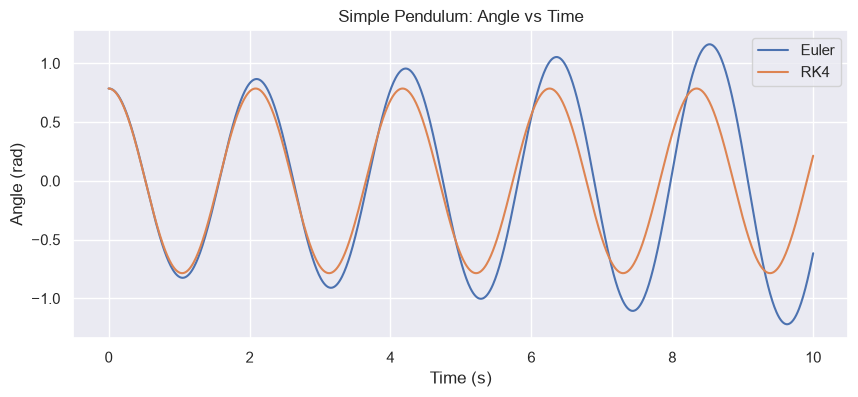

In [2]:
# practice mode

# global constants
g = 9.81
l = 1.0
    
def pendulum_ode(t, R):
    # R is a vector containing the two variables theta, omega
    # unpack R
    theta, omega = R
    # define f0 
    f0 = omega
    # define f1
    f1 = -g*np.sin(theta)/l
    return np.array([f0, f1])


# given time interval from 0 to 10 seconds sampled at 1000 pts, define a, b, n
a = 0
b = 10
n = 1000

# init conds (arbitrary): pi/4 angle, 0 initial velocity
yinit = np.array([np.pi/4, 0]) # theta0, omega0

def eulergen(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h

    # 2D array with n rows and 2 columns. 2 columns because we have two first order ODEs
    # generalize to m number of ODEs by using len(yinit)
    ys = np.zeros((n, len(yinit))) 

    # make a copy so that it doesn't modify the initial conditions
    y = yinit.copy()
    for j,x in enumerate(xs):
        # set current index in ys with the current y
        ys[j] = y
        # f(x, y) returns the slope, and then "walk forward" by multiplying this by the step size h
        y += h*f(x, y)
    return xs, ys

def rk4gen(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit)))
    y = yinit.copy()
    for j,x in enumerate(xs):
        # set current index in ys with the current y
        ys[j] = y
        # get the slope at k0 and "walk forward"
        k0 = h*f(x, y)
        # we walk forward half the step size this time
        # however we can use the original k0 slope to better approximate curved paths
        k1 = h*f(x+h/2, y+k0/2)
        # same idea with k1, but we use the k1 slope to get a better approximation
        k2 = h*f(x+h/2, y+k1/2)
        # now full step with the best slope approximation we have
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

t, Y_euler = eulergen(pendulum_ode, a, b, n, yinit)
t, Y_rk4 = rk4gen(pendulum_ode, a, b, n, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.title("Simple Pendulum: Angle vs Time")
plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.legend()
plt.show()


# include in discussion: "numerical heating"

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

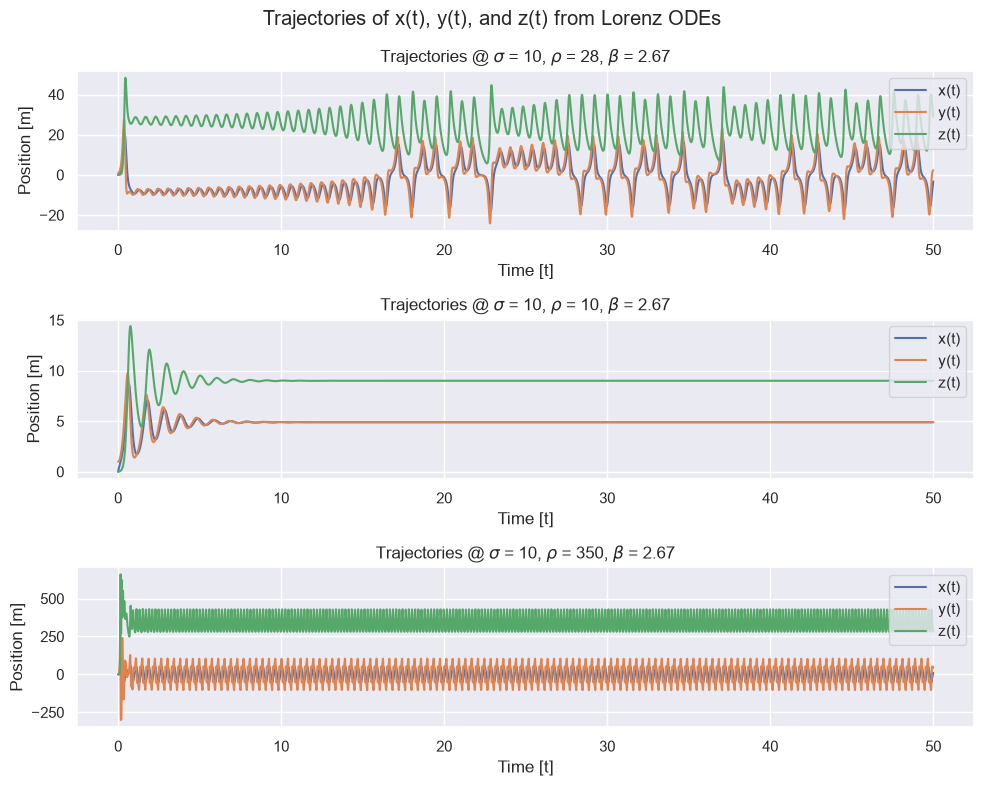

In [3]:
# consts
# different constants for chaotic attractor, stable fixed point, and stable periodic orbit
sigma_arr = [10, 10, 10]
rho_arr = [28, 10, 350]
beta_arr = [8/3, 8/3, 8/3]

# time
start = 0
end = 50
n = 5000

# initial conditions
yinit = np.array([0.0, 1.0, 0.0])

# the ODE
def lorenzODE(t, R, sigma, rho, beta):
    x, y, z = R
    # f0 = dx/dt; f1 = dy/dt; f2 = dz/dt
    f0 = sigma * (y - x)
    f1 = (rho * x) - y - (x * z)
    f2 = (x * y) - (beta * z)
    return np.array([f0, f1, f2])

'''
t, Y_rk4 = rk4gen(lorenzODE, start, end, n, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_rk4[:,0], label='x(t)')
plt.plot(t, Y_rk4[:,1], label='y(t)')
plt.plot(t, Y_rk4[:,2], label='z(t)')
plt.title("Trajectories of x(t), y(t) and z(t)")
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.legend()
plt.show()
'''

fig, axs = plt.subplots(3,1, figsize = (10,8))
for s, r, b, ax in zip(sigma_arr, rho_arr, beta_arr, axs):
    # create lambda wrapper to change the s, r, and b params
    lorenzCurrent = lambda t, R: lorenzODE(t, R, s, r, b)
    t, y = rk4gen(lorenzCurrent, start, end, n, yinit)
    ax.plot(t, y[:,0], label='x(t)')
    ax.plot(t, y[:,1], label='y(t)')
    ax.plot(t, y[:,2], label='z(t)')
    ax.set_xlabel('Time [t]')
    ax.set_ylabel('Position [m]')
    ax.set_title(fr"Trajectories @ $\sigma$ = {s}, $\rho$ = {r}, $\beta$ = {b:0.2f}")
    ax.legend(loc = 'upper right')
fig.suptitle("Trajectories of x(t), y(t), and z(t) from Lorenz ODEs")
fig.tight_layout()
plt.show()


**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

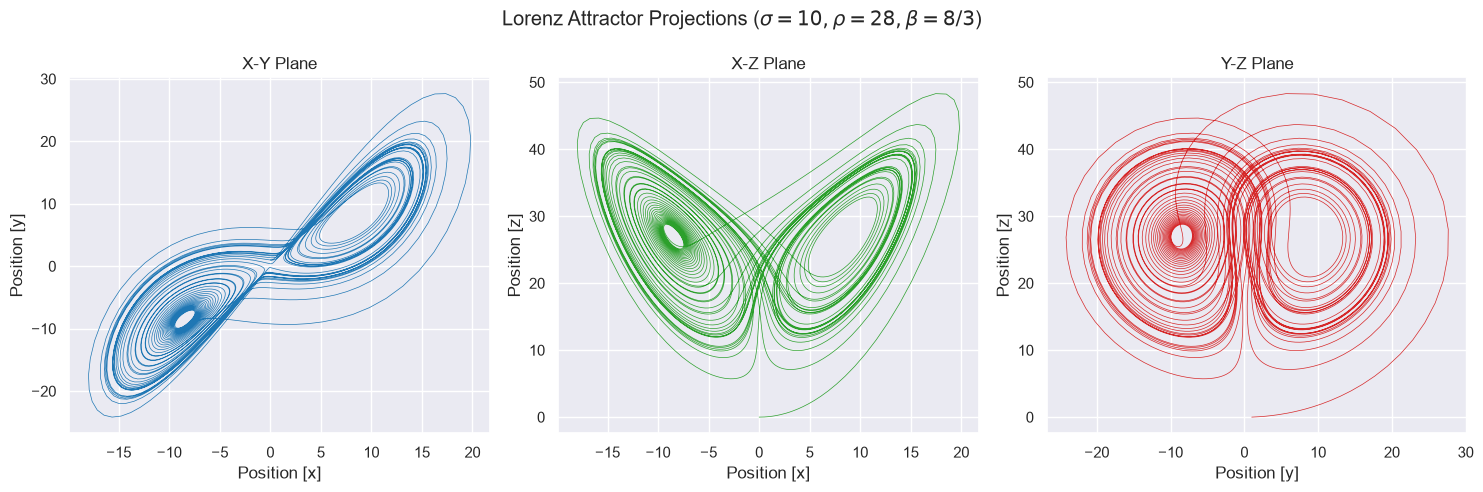

In [4]:
lorenzCurrent = lambda t, R: lorenzODE(t, R, sigma_arr[0], rho_arr[0], beta_arr[0])
t, y = rk4gen(lorenzCurrent, start, end, n, yinit)

fig, axs = plt.subplots(1, 3, figsize = (15, 5))

# x-y pln
axs[0].plot(y[:, 0], y[:, 1], color = 'tab:blue', linewidth = 0.5)
axs[0].set_title('X-Y Plane')
axs[0].set_xlabel("Position [x]")
axs[0].set_ylabel('Position [y]')

# x-z pln
axs[1].plot(y[:, 0], y[:, 2], color = 'tab:green', linewidth = 0.5)
axs[1].set_title('X-Z Plane')
axs[1].set_xlabel("Position [x]")
axs[1].set_ylabel('Position [z]')

# y-z pln
axs[2].plot(y[:, 1], y[:, 2], color = 'tab:red', linewidth = 0.5)
axs[2].set_title('Y-Z Plane')
axs[2].set_xlabel("Position [y]")
axs[2].set_ylabel('Position [z]')

fig.suptitle(r"Lorenz Attractor Projections ($\sigma=10, \rho=28, \beta=8/3$)")
plt.tight_layout()
plt.show()

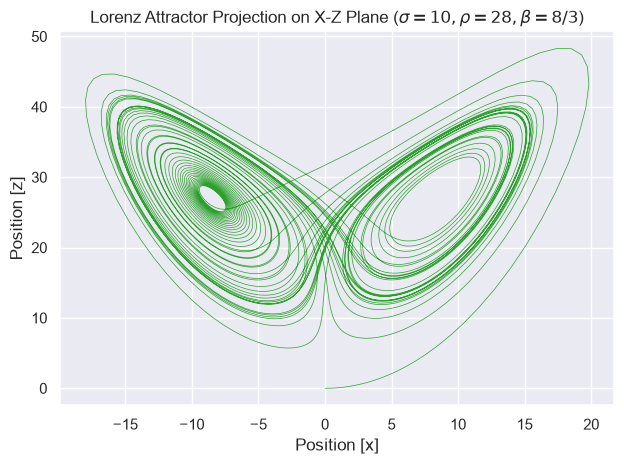

In [5]:
# figure 1 plotting: lorenz butterfly (x-z pln)
plt.plot(y[:, 0], y[:, 2], color = 'tab:green', linewidth = 0.5)
plt.title(r'Lorenz Attractor Projection on X-Z Plane ($\sigma=10, \rho=28, \beta=8/3$)')
plt.xlabel("Position [x]")
plt.ylabel('Position [z]')

plt.tight_layout()
plt.savefig('butterfly.png')
plt.show()

#### Problem 1 code summary

Made use of the RK4 algorithm because it was more accurate and converges much faster than Euler's method. I also defined the given ODE as a function (Lorenz) with some extra parameters ```sigma```, ```rho```, and ```beta``` so that instead of having to rewrite/redefine ```lorenzODE()``` for different parameters, I can quickly create a 'new' function by using the ```lambda``` function, letting ```t``` and ```R``` remain as arguments and setting the parameters so that they no longer become 'arguments' (for the new function). 

### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$ \frac{d^2x}{dt^2} = - \omega^2 x $.

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

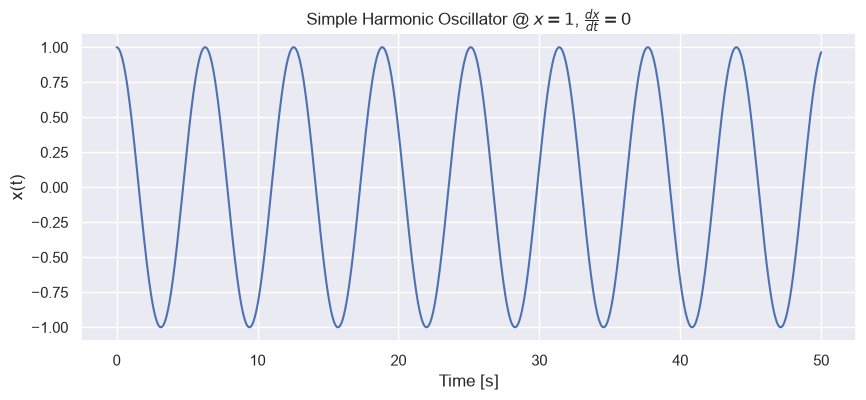

Period: 6.2813 s


In [6]:
# inits
start = 0
end = 50
n = 1000

# consts
omega = 1

def harmonicOscillator(t, R):
    x, y = R
    # f0 = dx/dt, f1 = dy/dt
    f0 = y
    f1 = -(omega**2)*x
    return np.array([f0, f1])

yinit = [1.0, 0.0] # x = 1, y = dx/dt = 0

t, y = rk4gen(harmonicOscillator, start, end, n, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, y[:, 0])
plt.xlabel("Time [s]")
plt.ylabel("x(t)")
plt.title(r"Simple Harmonic Oscillator @ $x = 1$, $\frac{dx}{dt} = 0$")
plt.show()

x = y[:, 0]
peak_indices = np.where((x[1:-1] > x[:-2]) & (x[1:-1] > x[2:]))[0] + 1
period = np.mean(np.diff(t[peak_indices]))
print(f"Period: {period:.4f} s")

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

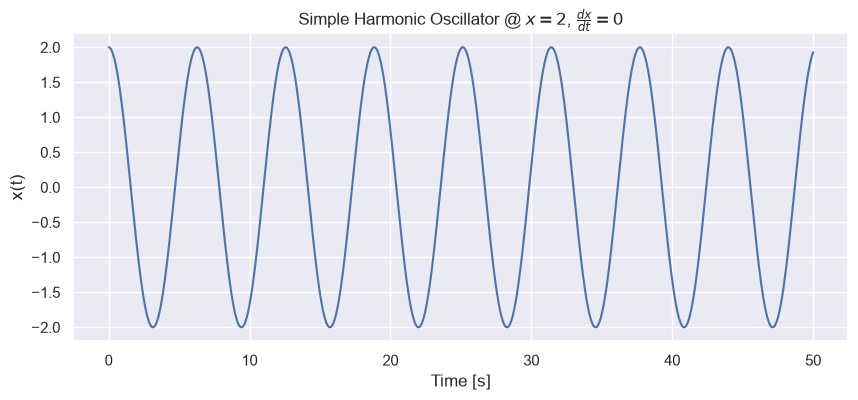

Period: 6.2813 s


In [7]:

yinit = [2.0, 0.0] # x = 2, y = dx/dt = 0

t, y = rk4gen(harmonicOscillator, start, end, n, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, y[:, 0])
plt.xlabel("Time [s]")
plt.ylabel("x(t)")
plt.title(r"Simple Harmonic Oscillator @ $x = 2$, $\frac{dx}{dt} = 0$")
plt.show()

x = y[:, 0]
peak_indices = np.where((x[1:-1] > x[:-2]) & (x[1:-1] > x[2:]))[0] + 1
period = np.mean(np.diff(t[peak_indices]))
print(f"Period: {period:.4f} s")

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt^2} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

$$ \frac{d^2 x}{dt^2} = -\omega^2 x^3.$$

rewrite as
$$\frac{dx}{dt} = y$$
$$\frac{dy}{dt} = -\omega^2 x^3$$

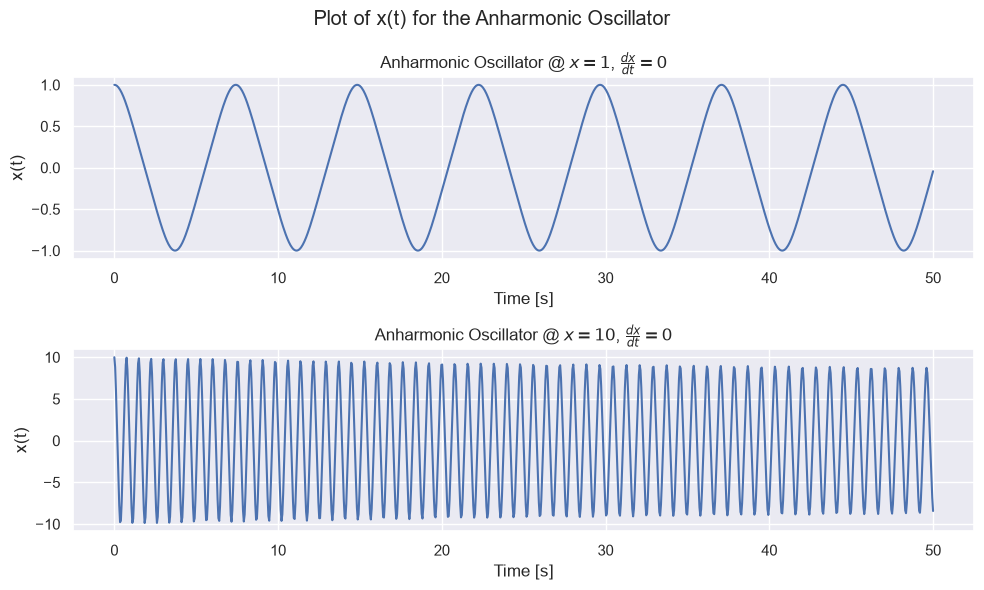

In [8]:
# consts
omega = 1

def anharmonicOscillator(t, R):
    x, y = R
    # f0 = dx/dt, f1 = dy/dt
    f0 = y
    f1 = -(omega**2)*(x**3)
    return np.array([f0, f1])

# for x = 1, dx/dt = 0
start = 0
end = 50
n = 1000
yinit = [1.0, 0.0] # x = 1, y = dx/dt = 0

t_1, y_1 = rk4gen(anharmonicOscillator, start, end, n, yinit)

fig, axs = plt.subplots(2,1, figsize=(10,6))
axs[0].plot(t_1, y_1[:, 0])
axs[0].set_xlabel("Time [s]")
axs[0].set_ylabel("x(t)")
axs[0].set_title(r"Anharmonic Oscillator @ $x = 1$, $\frac{dx}{dt} = 0$")

# lets try x = 10
start = 0
end = 50
n = 1000
yinit = [10.0, 0.0]

t_50, y_50 = rk4gen(anharmonicOscillator, start, end, n, yinit)
axs[1].plot(t_50, y_50[:, 0])
axs[1].set_xlabel("Time [s]")
axs[1].set_ylabel("x(t)")
axs[1].set_title(r"Anharmonic Oscillator @ $x = 10$, $\frac{dx}{dt} = 0$")

plt.suptitle("Plot of x(t) for the Anharmonic Oscillator")
plt.tight_layout()
plt.show()

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

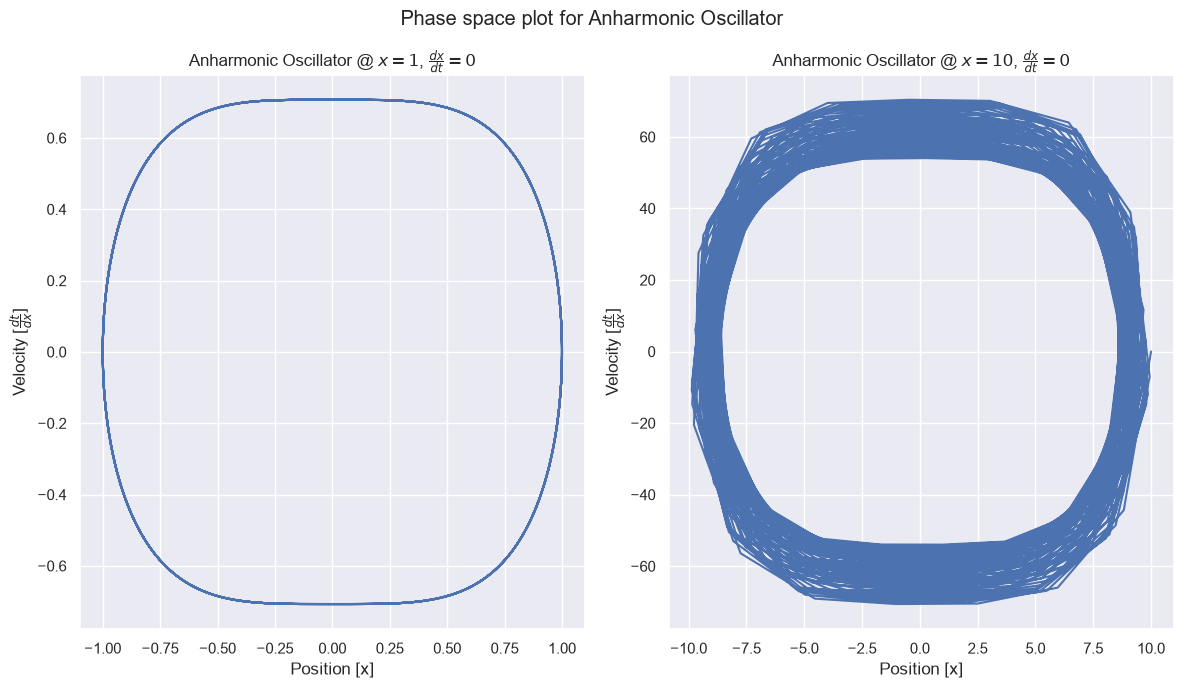

In [9]:
#for x = 1
fig, axs = plt.subplots(1,2, figsize=(12,7))
axs[0].plot(y_1[:, 0], y_1[:, 1])
axs[0].set_xlabel("Position [x]")
axs[0].set_ylabel(r"Velocity [$\frac{dt}{dx}$]")
axs[0].set_title(r"Anharmonic Oscillator @ $x = 1$, $\frac{dx}{dt} = 0$")

# for x = 10
axs[1].plot(y_50[:, 0], y_50[:, 1])
axs[1].set_xlabel("Position [x]")
axs[1].set_ylabel(r"Velocity [$\frac{dt}{dx}$]")
axs[1].set_title(r"Anharmonic Oscillator @ $x = 10$, $\frac{dx}{dt} = 0$")

plt.suptitle("Phase space plot for Anharmonic Oscillator")
plt.tight_layout()
plt.show()

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

rewrite:
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$

$$ \frac{dx}{dt} = y$$

$$ \frac{dy}{dt} - \mu(1-x^2)y + x = 0$$

$$ \frac{dy}{dt} = \mu(1-x^2)y - x $$


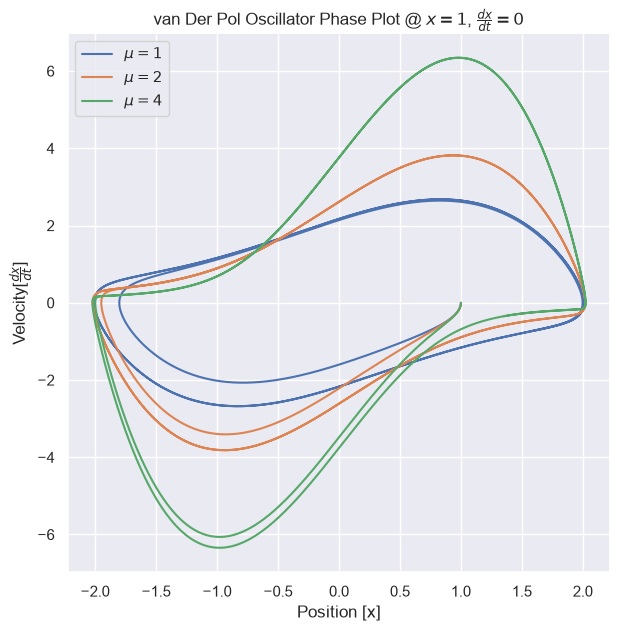

In [10]:
# consts
mu = 1
omega = 1

def vanDerPol(t, R, mu):
    x, y = R
    #f0 = dx/dt, f1 = dy/dt
    f0 = y
    f1 = mu*(1-x**2)*y - x

    return np.array([f0, f1])

# init val
start = 0
end = 20
n = 10000
# x = 1; dx/dt = 0
yinit = [1.0, 0.0]

vanDerPol_mu1 = lambda t, R: vanDerPol(t, R, 1)
vanDerPol_mu2 = lambda t, R: vanDerPol(t, R, 2)
vanDerPol_mu4 = lambda t, R: vanDerPol(t, R, 4)

tv_1, yv_1 = rk4gen(vanDerPol_mu1, start, end, n, yinit)
tv_2, yv_2 = rk4gen(vanDerPol_mu2, start, end, n, yinit)
tv_4, yv_4 = rk4gen(vanDerPol_mu4, start, end, n, yinit)


plt.figure(figsize=(7,7))
plt.plot(yv_1[:, 0], yv_1[:, 1], label = r'$\mu = 1$')
plt.plot(yv_2[:, 0], yv_2[:, 1], label = r'$\mu = 2$')
plt.plot(yv_4[:, 0], yv_4[:, 1], label = r'$\mu = 4$')
plt.ylabel(r"Velocity[$\frac{dx}{dt}$]")
plt.xlabel(r"Position [x]")
plt.legend()
plt.title(r"van Der Pol Oscillator Phase Plot @ $x = 1$, $\frac{dx}{dt} = 0$")
plt.savefig("vanderpol.png")
plt.show()

#### Problem 2 code summary

I rewrote the simple, anharmonic, and van Der Pol oscillators as a system of linear ODEs so that I can write them as a function of ```t``` and ```R```. As for the ```vanDerPol()```, similar to problem 1, I wrote it with an extra parameter ```mu``` so that I can quickly create a new function by calling ```lambda``` so I can set mu to be anything without having to redefine the function explicitly.

Having the ```rk4gen()``` function return a numpy array of ```f0``` and ```f1``` made it easier to switch from a time-series plot of x against time to a phase plot (dx/dt against x) since f0 is the position and f1 is the velocity; its just a matter of replacing the "x" array in plotting with the position (```yv_n[:, 0]```) and then "y" array with velocity (```yv_n[:, 1]```).

---
## Section 3: Notes

In [11]:
# forward Euler's method

def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

In [12]:
# 2nd order Runge-Kutta method

def rk2(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k1 = h*f(x, y)
        k2 = h*f(x+0.5*h, y+0.5*k1)
        y += k2
    return xs, ys

In [13]:
# 4th order Runge-Kutta method (1 equation only, use the code below for simultaneous eqns)

def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

#### Solving IVP problem of 2 simultaneous ODEs

In [14]:
def eulergen(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) 
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

### Plotting

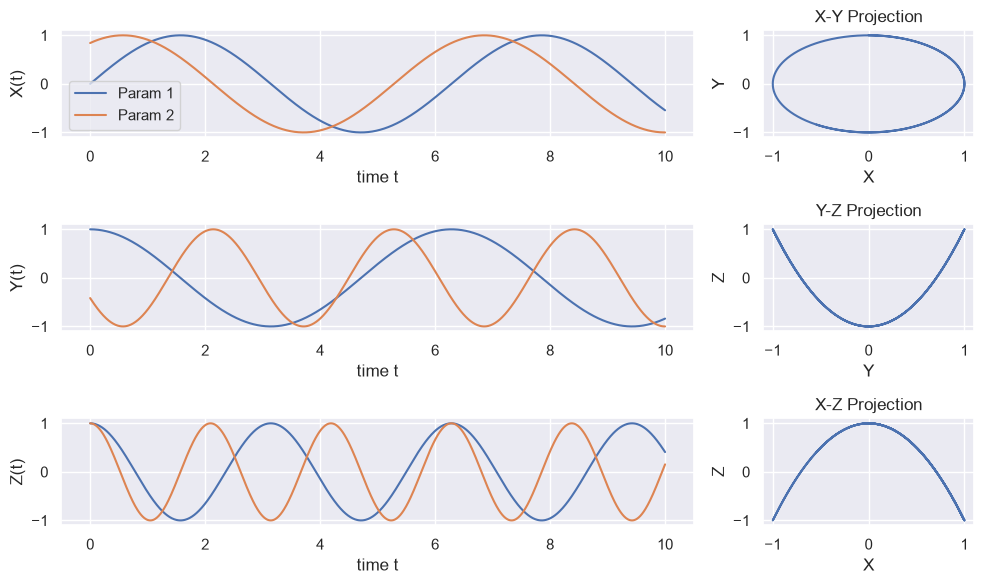

In [15]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)

# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()